# Actividad 2. Análisis de datos pesqueros de Celestún

En esta actividad se realizará un análisis exploratorio de una base de datos correspondiente a entrevistas pesqueras
realizadas en Celestún, Yucatán. La base de datos utilizada, denominada hackaton_kact.xlsx, 
contiene información sobre las características de las embarcaciones, el esfuerzo pesquero, las artes de pesca y
la composición de las capturas.
El objetivo es aplicar herramientas de programación en Python para explorar la información mediante visualizaciones
y desarrollar funciones sencillas que permitan realizar cálculos de interés pesquero.
Se abordarán tres aspectos principales: La distribución temporal de las entrevistas por año y mes, la composición de las capturas
por categorías de especies y el cálculo de la captura por unidad de esfuerzo (CPUE).


## 2. Importación de bibliotecas
Para realizar el análisis exploratorio y la visualización de los datos, se utilizarán diferentes bibliotecas de Python. Estas herramientas permitirán organizar la información, realizar operaciones numéricas y generar representaciones gráficas.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


## 3. Carga y exploración de la base de datos
Se importará la base de datos de entrevistas pesqueras de Celestún, previamente depurada y organizada en formato Excel.
Posteriormente, se revisarán sus dimensiones, encabezados y tipos de datos para comprobar que la información se haya
cargado correctamente.

In [18]:
datos = pd.read_excel("hackaton_kact.xlsx")

In [19]:
datos.head()

,ID bis,ID,SP OBJETIVO,ZONA,LUGAR,FECHA,# BOTE,NOMBRE PESCADOR,Motor Marca 1,HP1,...,LANGOSTA VIVA GDE,LANGOSTA 2a,OTRAS Sps,FILETE,OBSERVACIONES 1,OBSERVACIONES 2,LANCHON,OBSERVACIONES DE ARTES DE PESCA,LONGITUD_1,LATITUD_1
0,127.0,127,RUBIA-CANANÉ,PONIENTE,CELESTÚN,2013-07-19,127,NaN,YAMAHA,50.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,128.0,128,RUBIA-CANANÉ,PONIENTE,CELESTÚN,2013-07-19,128,NaN,YAMAHA,85.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,129.0,129,RUBIA-CANANÉ,PONIENTE,CELESTÚN,2013-07-19,129,NaN,YAMAHA,85.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,130.0,130,RUBIA-CANANÉ,PONIENTE,CELESTÚN,2013-07-19,130,NaN,YAMAHA,50.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,265.0,265,RUBIA-CANANÉ,PONIENTE,CELESTÚN,2013-10-17,265,NaN,YAMAHA,60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
print(datos.shape)
datos.info()


(749, 236)
<class 'pandas.DataFrame'>
RangeIndex: 749 entries, 0 to 748
Columns: 236 entries, ID bis to LATITUD_1
dtypes: datetime64[us](1), float64(203), object(16), str(16)
memory usage: 1.4+ MB


### 3.1. Dimensiones y estructura de la base
Se realizó una exploración inicial de la base de datos para identificar el número de registros y variables disponibles,
así como los tipos de datos y la presencia de valores faltantes.

In [24]:
# Consultar las dimensiones de la base
print("Número de entrevistas:", datos.shape[0])
print("Número de variables:", datos.shape[1])

# Consultar los tipos de datos
datos.info()

Número de entrevistas: 749
Número de variables: 236
<class 'pandas.DataFrame'>
RangeIndex: 749 entries, 0 to 748
Columns: 236 entries, ID bis to LATITUD_1
dtypes: datetime64[us](1), float64(203), object(16), str(16)
memory usage: 1.4+ MB


### 3.2. Revisión y preparación de fechas

Se revisó la variable FECHA para verificar su formato y asegurar que los registros
pudieran organizarse cronológicamente por año y mes.

In [25]:
# Revisar el tipo de dato de FECHA
print("Tipo de dato:", datos["FECHA"].dtype)

# Mostrar las primeras diez fechas
datos["FECHA"].head(10)

Tipo de dato: datetime64[us]


0   2013-07-19
1   2013-07-19
2   2013-07-19
3   2013-07-19
4   2013-10-17
5   2013-10-17
6   2013-10-17
7   2013-10-17
8   2013-10-17
9   2013-10-17
Name: FECHA, dtype: datetime64[us]

In [26]:
# Identificar valores faltantes en la variable FECHA
print("Fechas faltantes:", datos["FECHA"].isna().sum()) 

Fechas faltantes: 1


## 4. Cobertura temporal de las entrevistas

Se analizó la distribución temporal de los registros de entrevistas pesqueras para identificar los años y meses con mayor y menor cobertura de información.

### 4.1. Preparación de las variables temporales

A partir de la variable FECHA se extrajeron el año y el mes de cada registro. Esto permitirá agrupar las entrevistas y analizar su distribución temporal.

In [27]:
# Extraer el año y el mes de cada entrevista

datos["AÑO"] = datos["FECHA"].dt.year
datos["MES"] = datos["FECHA"].dt.month

# Revisar las nuevas variables

datos[["FECHA", "AÑO", "MES"]].head(10)

/tmp/ipykernel_394/3325611279.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["AÑO"] = datos["FECHA"].dt.year
/tmp/ipykernel_394/3325611279.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos["MES"] = datos["FECHA"].dt.month


,FECHA,AÑO,MES
0,2013-07-19,2013.0,7.0
1,2013-07-19,2013.0,7.0
2,2013-07-19,2013.0,7.0
3,2013-07-19,2013.0,7.0
4,2013-10-17,2013.0,10.0
5,2013-10-17,2013.0,10.0
6,2013-10-17,2013.0,10.0
7,2013-10-17,2013.0,10.0
8,2013-10-17,2013.0,10.0
9,2013-10-17,2013.0,10.0


### 4.2. Distribución de entrevistas por año y mes

Se agruparon los registros según el año y el mes de realización. Posteriormente, se construyó una tabla de frecuencias que permite identificar el número de entrevistas registradas en cada periodo.

In [31]:
# Contar registros por año y mes
datos["AÑO"] = datos["AÑO"].astype("Int64")

entrevistas_mes = (
    datos.groupby(["AÑO", "MES"])
    .size()
    .unstack(fill_value=0)
)

# Asegurar que aparezcan los 12 meses
entrevistas_mes = entrevistas_mes.reindex(
    columns=range(1, 13),
    fill_value=0
)

entrevistas_mes

MES,1,2,3,4,5,6,7,8,9,10,11,12
AÑO,,,,,,,,,,,,
2013,0,0,0,0,0,0,4,0,0,7,0,0
2015,0,0,29,33,44,27,32,5,20,17,0,12
2017,0,0,29,23,20,24,40,0,24,18,31,0
2019,0,0,24,25,19,18,12,11,5,0,12,15
2021,0,0,38,18,24,12,12,0,0,17,12,0
2023,0,0,0,14,7,6,6,0,2,0,0,0


In [32]:
# Cambiar los números de los meses por sus nombres

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

entrevistas_mes.columns = nombres_meses

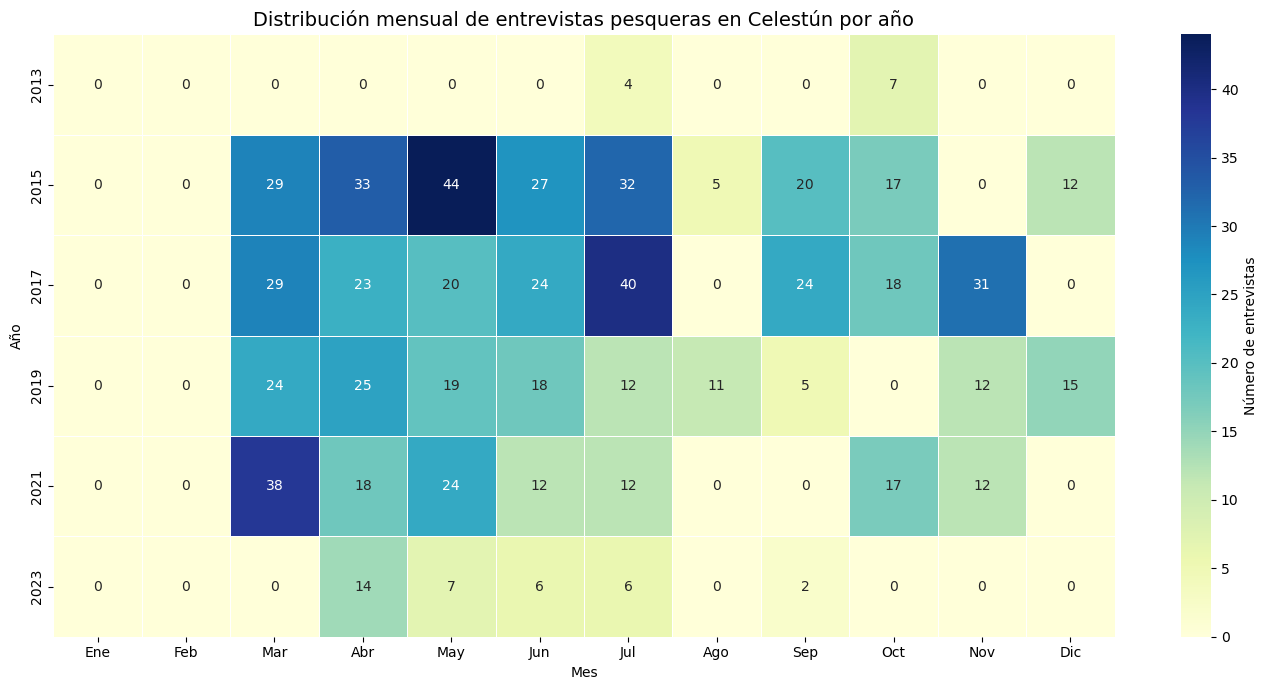

In [33]:
# Crear un mapa de calor para visualizar esta información

plt.figure(figsize=(14, 7))

sns.heatmap(
    entrevistas_mes,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Número de entrevistas"}
)

plt.title("Distribución mensual de entrevistas pesqueras en Celestún por año",
          fontsize=14)

plt.xlabel("Mes")
plt.ylabel("Año")

plt.tight_layout()
plt.show()

## 5. Composición de las capturas

Se analizará la contribución porcentual de las diferentes categorías de especies al volumen total de captura registrado en Celestún.

In [34]:
# Identificar las columnas de captura por especie

posicion = datos.columns.get_loc("CAPTURA (kg)")

columnas_captura = datos.columns[posicion + 1:]

# Calcular la captura acumulada por columna
capturas = datos[columnas_captura].select_dtypes(
    include="number"
).sum()

# Mostrar las 15 categorías con mayor captura
capturas.sort_values(ascending=False).head(15)

AÑO                    1509258.0
SARDINA                 112440.0
MERO MED                 6006.47
JUREL                     5506.0
RUBIA GDE.              5223.261
BONITO                    5200.0
CANANE GDE              5018.735
MES                       4752.0
LATITUD_1             2869.02051
RUBIA CH                 2279.86
CHAC-CHI                  2229.8
BALA (raya látigo)        2005.0
MERO GDE                 1549.48
NEGRILLO GDE            1150.215
CANANE CH               1132.295
dtype: Float64

### 5.1. Agrupación de especies

Se agruparon las diferentes presentaciones comerciales de las especies en categorías generales. Para ello, se sumaron las cantidades capturadas correspondientes a las distintas tallas y presentaciones de cada grupo, expresadas en kilogramos.

Se excluyeron las categorias correspondientes a "virula, filete y otras especies", debido a que no forman parte de las categorías "especies" o no son específicas para considerarlas en esta representación.

In [52]:

# 1. Homogenizar los nombres de las columnas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata

def normalizar_columna(nombre):
    nombre = str(nombre).upper().strip()

    # Quitar comillas accidentales
    nombre = nombre.replace('"', '').replace("'", '')

    # Quitar acentos
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        caracter for caracter in nombre
        if not unicodedata.combining(caracter)
    )

    # Convertir espacios repetidos en uno solo
    nombre = re.sub(r"\s+", " ", nombre)

    # Quitar espacios y signos de puntuación para comparar
    nombre = re.sub(r"[^A-Z0-9]", "", nombre)

    return nombre


# Crear índice de nombres normalizados
indice_columnas = {}

for posicion, columna in enumerate(datos.columns):
    clave = normalizar_columna(columna)
    indice_columnas.setdefault(clave, []).append(posicion)


# 2. Agrupar comlumnas por especie

categorias = {

    "Meros": ["MERO CH", "MERO MED", "MERO MED 3-5",
              "MERO MED 5 UP", "MERO GDE", "MERO ROJO"],

    "Negrillos": ["NEGRILLO MED", "NEGRILLO GDE"],

    "Abadejos": ["ABADEJO MED", "ABADEJO GDE"],

    "Gallina": ["GALLINA"],

    "Payasos": ["PAYASO", "PAYASO CH"],

    "Cherna": ["CHERNA"],

    "Rubias": ["RUBIA CH", "RUBIA GDE."],

    "Cananés": ["CANANE CH", "CANANE GDE"],

    "Pargos": ["PARGO", "P. MULATO CH", "P. MULATO MED",
               "P. MULATO   MED", "P. MULATO GDE",
               "PARGO PERRO", "PARGO LUNAR CRIOLLO"],

    "Boquinete": ["BOQUINETE CH", "BOQUINETE MED",
                  "BOQUINETE GDE 1RA", "BOQUINETE PLUS",
                  "BOQUINETE MED 2DA_1"],

    "Chac-chi": ["CHAC-CHI"],

    "Coronado": ["CORONADO"],

    "Mojarras": ["CACHIPLUMAS, MOJARRAS", "MOJARRON, BURRA_1"],

    "Esmedregales": ["ESMEDREGAL", "ESMEDREGAL LIMON",
                     "ESMEDREGAL CORONADO_1"],

    "Picuda": ["PICUDA"],

    "Cazones": ["CAZON", "CAZON CH", "CAZÓN DE LEY_1",
                "CAZON LIMON O AMARILLO_1"],

    "Tiburones": ["TIBURON_1", "CORNUDA_1", "GATA"],

    "Rayas": ["BALA (raya látigo)", "RAYA PINTA"],

    "Sierra": ["SIERRA"],

    "Carito": ["CARITO"],

    "Sardina": ["SARDINA"],

    "Escribano": ["ESCRIBANO"],

    "Róbalos": ["ROBALO MED", "ROBALO GDE"],

    "Ronco": ["RONCO_1"],

    "Corvinas": ["CORVINA PINTA", "CORVINA BLANCA"],

    "Bonito": ["BONITO"],

    "Sargo y poshta": ["SARGO, POSHTA"],

    "Lisa y liseta": ["LISA", "LISETA"],

    "Cojinudas": ["COJINUDA CARBONERA (ruber)",
                  "COJINUDA NEGRA (chrysos)"],

    "Pámpano": ["PAMPANO"],

    "Palometa": ["PALOMETA"],

    "Papelillo": ["PAPELILLO"],

    "Jureles": ["JUREL", "JUREL BLANCO"],

    "Bagre": ["BAGRE"],

    "Dorado": ["DORADO"],

    "Pulpo": ["PULPO", "PULPO CH", "PULPO MED",
              "PULPO GDE", "PULPO PLUS"],

    "Langosta": ["LANGOSTA", "LANGOSTA VIVA CH",
                 "LANGOSTA VIVA GDE", "LANGOSTA 2a"]
}

# 3. Revisar que las columnas hayan quedado correctamente 

columnas_por_categoria = {}
columnas_faltantes = {}

for categoria, nombres in categorias.items():

    posiciones = []
    faltantes = []

    for nombre in nombres:
        clave = normalizar_columna(nombre)

        coincidencias = indice_columnas.get(clave, [])

        if coincidencias:
            posiciones.extend(coincidencias)
        else:
            faltantes.append(nombre)

    # Evitar repetir una misma posición
    posiciones = list(dict.fromkeys(posiciones))

    if posiciones:
        columnas_por_categoria[categoria] = posiciones

    if faltantes:
        columnas_faltantes[categoria] = faltantes


print("COLUMNAS IDENTIFICADAS POR CATEGORÍA:\n")

for categoria, posiciones in columnas_por_categoria.items():
    nombres_reales = [datos.columns[i] for i in posiciones]
    print(f"{categoria}: {nombres_reales}")


print("\nCOLUMNAS NO ENCONTRADAS:\n")

if columnas_faltantes:
    for categoria, faltantes in columnas_faltantes.items():
        print(f"{categoria}: {faltantes}")
else:
    print("Todas las columnas del diccionario fueron encontradas.")



COLUMNAS IDENTIFICADAS POR CATEGORÍA:

Meros: ['$_MERO CH', 'MERO CH', '$_MERO MED', 'MERO MED', '$_MERO MED 3-5', 'MERO MED 3-5', 'MERO MED 5 UP', '$_MERO GDE', 'MERO GDE', '$_MERO ROJO', 'MERO ROJO']
Negrillos: ['$_NEGRILLO MED', 'NEGRILLO MED', '$_NEGRILLO GDE', 'NEGRILLO GDE']
Abadejos: ['$_ABADEJO MED', 'ABADEJO MED', '$_ABADEJO GDE', 'ABADEJO GDE']
Gallina: ['$_GALLINA', 'GALLINA']
Payasos: ['$_PAYASO', 'PAYASO', '$_PAYASO CH', 'PAYASO CH']
Cherna: ['$_CHERNA', 'CHERNA']
Rubias: ['$_RUBIA CH', 'RUBIA CH', '$_RUBIA GDE.', 'RUBIA GDE.']
Cananés: ['$_CANANE CH', 'CANANE CH', '$_CANANE GDE', 'CANANE GDE']
Pargos: ['$_PARGO', 'PARGO', 'P. MULATO CH', 'P. MULATO  MED', 'P. MULATO GDE', '$_PARGO PERRO', 'PARGO PERRO', '$_PARGO LUNAR CRIOLLO', 'PARGO LUNAR CRIOLLO']
Boquinete: ['$_BOQUINETE CH', 'BOQUINETE CH', '$_BOQUINETE MED', 'BOQUINETE MED', 'BOQUINETE GDE 1RA', '$_BOQUINETE PLUS', 'BOQUINETE PLUS', 'BOQUINETE MED 2DA_1']
Chac-chi: ['$_CHAC-CHI', 'CHAC-CHI']
Coronado: ['$_CORONADO',


## 6. Función para calcular la composición de la captura

Se desarrolló una función en Python para calcular la captura total registrada por cada categoría de especie y determinar su contribución porcentual respecto a la captura total.

La función permite agrupar diferentes categorías comerciales de una misma especie, sumar sus registros de captura y obtener una tabla ordenada de mayor a menor contribución.



In [63]:
# Calcular la composición porcentual de la captura

#mejorar estructura 

def calcular_composicion(datos, columnas_por_categoria):

    resultados = {}

    for categoria, posiciones in columnas_por_categoria.items():

        # Extraer exclusivamente las columnas identificadas
        captura = datos.iloc[:, posiciones].copy()

        # Convertir valores a números
        captura = captura.apply(
            lambda columna: pd.to_numeric(columna, errors="coerce")
        )

        # Sumar las capturas de cada categoría
        total = captura.sum(axis=1, min_count=1).sum(min_count=1)

        resultados[categoria] = total

    composicion = pd.Series(resultados, name= "Captura (kg)")

    # Conservar únicamente categorías con captura positiva
    composicion = composicion[composicion > 0]

    porcentaje = composicion / composicion.sum() * 100

    resultado = pd.DataFrame({
        "Captura (kg)": composicion,
        "Porcentaje (%)": porcentaje
    })

    return resultado.sort_values(
        "Captura (kg)", ascending=False
    )


#Funcion para el calculo 

composicion = calcular_composicion(
    datos,
    columnas_por_categoria
)

display(composicion.round(2))


,Captura (kg),Porcentaje (%)
Sardina,124246.20,28.93
Meros,62467.90,14.55
Negrillos,40935.73,9.53
Abadejos,40616.00,9.46
Langosta,37673.86,8.77
Cananés,32032.03,7.46
Rubias,30604.12,7.13
Pargos,10406.17,2.42
Jureles,8405.80,1.96
Pulpo,6727.20,1.57


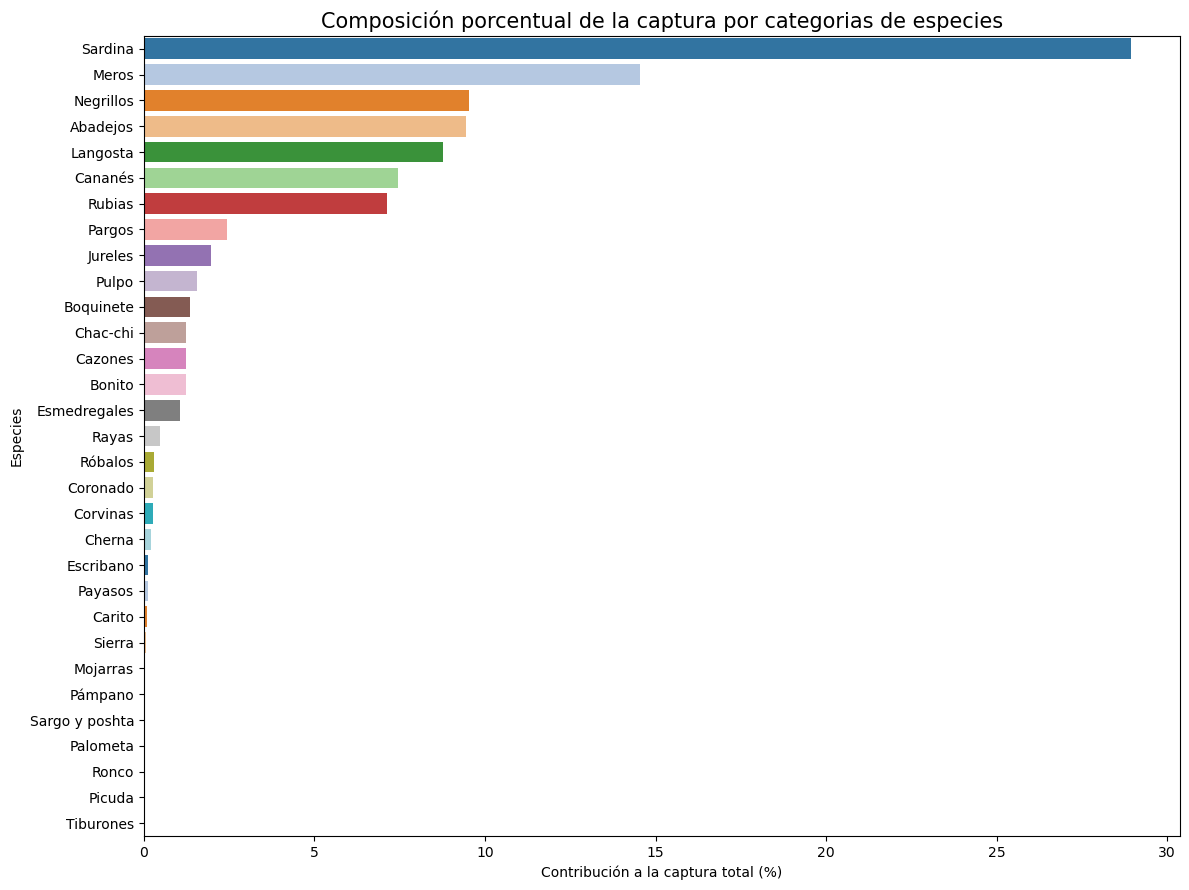

In [65]:

# Graficar la composición de captura por cada especie 

plt.figure(figsize=(12, 9))

sns.barplot(
    data=composicion.reset_index(),
    x="Porcentaje (%)",
    y="index",
    hue="index",
    palette="tab20",
    legend=False
)

plt.title(
    "Composición porcentual de la captura por categorias de especies",
    fontsize=15
)

plt.xlabel("Contribución a la captura total (%)")
plt.ylabel("Especies")

plt.tight_layout()
plt.show()



## 8. Conclusiones

El análisis exploratorio de la base de datos pesquera de Celestún permitió identificar patrones en la distribución temporal de las entrevistas y describir la composición de las capturas registradas.

La representación mediante un mapa de calor permitió visualizar cómo se distribuyen las entrevistas entre los diferentes años y meses, identificando periodos con mayor y menor cantidad de registros. Por otra parte, el análisis de composición permitió agrupar las distintas categorías comerciales de las especies y calcular su contribución porcentual a la captura total.

El desarrollo de funciones en Python facilitó la automatización de los cálculos y permitió organizar la información para su posterior representación gráfica. Esto demuestra la utilidad de herramientas de programación para explorar y analizar bases de datos pesqueras.

Sin embargo, los resultados deben interpretarse considerando las limitaciones de la información disponible. La cantidad de entrevistas registradas no representa necesariamente el esfuerzo pesquero real, y la composición calculada corresponde únicamente a las especies y categorías incluidas en el análisis. Por lo tanto, estos resultados describen los registros disponibles, pero no deben considerarse como una representación completa de toda la actividad pesquera de Celestún.

En conjunto, esta actividad permitió aplicar herramientas de Python para la exploración, visualización y análisis de información pesquera. :)
